# Hälsostudie

## Slutsats och rekommendation

- **Andel sjuka**: ≈ 5,9 % i datan (47 av 800). Simuleringen gav 5,4 %, en skillnad som ryms inom standardfelet (≈ 0,7 procentenheter).
- **Blodtryck**: medelvärdet är ≈ **149,2 mmHg** (95 % KI ≈ 148,3–150,1 mmHg). t-fördelning och bootstrap ger nästan samma intervall.
- **Rökare vs icke-rökare**: vi hittar **inget stöd** för att rökare har högre blodtryck (p ≈ 0,33). Skillnaden är bara ≈ 0,47 mmHg.
- **Ålder och blodtryck**: blodtrycket ökar med ungefär **0,54 mmHg per år** (R² ≈ 0,37). Med vikt som extra variabel stiger R² bara till ≈ 0,41.

**Rekommendation:** En linjär modell med ålder (och eventuellt vikt) kan användas för att göra en första prognos av blodtryck. Modellen förklarar ändå bara ca 40 % av variationen, så fler variabler behövs för bättre prognoser.
Vill man veta om rökning påverkar blodtrycket behövs fler personer i studien. Testet hittar bara skillnader på ca 2,6 mmHg eller mer. Att vi inte fann stöd för en skillnad betyder alltså inte att ingen skillnad finns. Sambanden visar inte heller vad som orsakar vad.

In [1]:
import pandas as pd
import numpy as np

from src.analyzer import HealthAnalyzer

df = pd.read_csv("health_study_dataset.csv")
ha = HealthAnalyzer(df)

In [2]:
print(f"Datamängdens storlek: {len(df)}")

display(df.info())

Datamängdens storlek: 800
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
 9   bmi          800 non-null    float64
dtypes: float64(5), int64(3), str(2)
memory usage: 62.6 KB


None

## Beskrivande analys

In [3]:
ha.calculate_avg()

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### Korrelationstabell

In [4]:
ha.correlation()

,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease,bmi
age,1.00,-0.03,-0.00,-0.02,0.61,0.49,0.04,0.02,-0.01
sex,-0.03,1.00,0.69,0.46,0.08,0.05,-0.05,0.06,0.03
height,-0.00,0.69,1.00,0.32,0.09,-0.04,-0.05,0.03,-0.30
weight,-0.02,0.46,0.32,1.00,0.18,0.26,0.02,0.04,0.80
systolic_bp,0.61,0.08,0.09,0.18,1.00,0.37,0.02,0.03,0.13
cholesterol,0.49,0.05,-0.04,0.26,0.37,1.00,0.01,0.01,0.29
smoker,0.04,-0.05,-0.05,0.02,0.02,0.01,1.00,0.08,0.05
disease,0.02,0.06,0.03,0.04,0.03,0.01,0.08,1.00,0.02
bmi,-0.01,0.03,-0.30,0.80,0.13,0.29,0.05,0.02,1.00


### Diagram

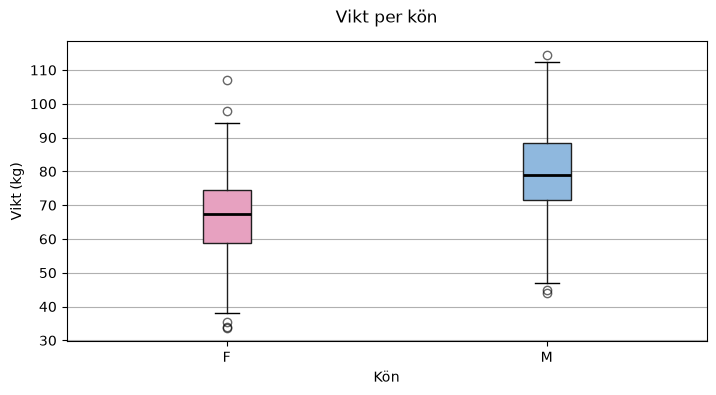

In [5]:
ha.plot("weight")

Män har högre medianvikt än kvinnor. Det finns några extremvärden i båda grupperna.

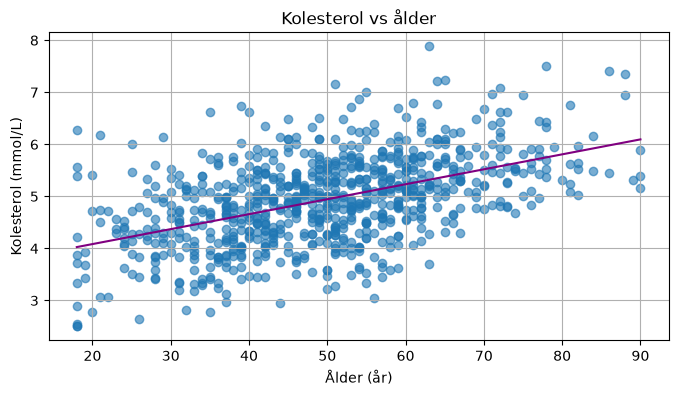

In [6]:
ha.plot("cholesterol")

Korrelationen mellan Kolesterol och ålder är ≈ 0,49. Punkterna visar att kolesterolet tenderar att öka med åldern, men spridningen är stor.

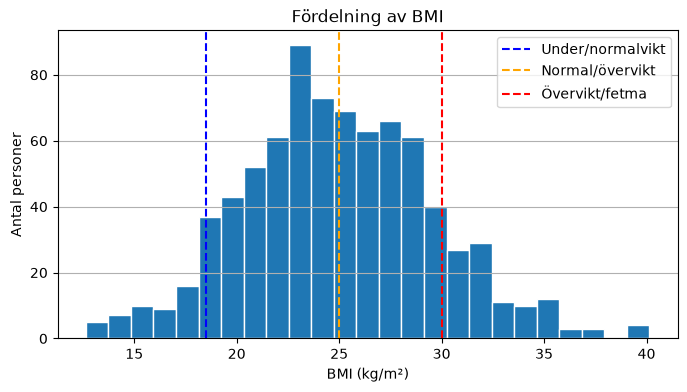

In [7]:
ha.plot("bmi")

Normalvikt (BMI 18,5–24,9) är den vanligaste kategorin, men många ligger inom övervikt (25–29,9) och fetma (30 eller mer).

## Simulering: andel sjuka

In [8]:
d_text, d_comparison = ha.disease_simulation()
print(d_text)
display(d_comparison)


    Totalt antal personer med sjukdomen: 47 av 800
    Andelen personer med sjukdomen: 0.05875 (5.875%)
    Standardfel (SE): 0.744%
    


,Antal personer,Antal sjuka,Andel sjuka
Dataset,800,47,5.875%
Simulering,1000,54,5.400%


Andelen sjuka i datasetet är 5,875 % (47 av 800). I simuleringen med 1000 personer blev andelen 5,4 %. Skillnaden på ungefär 0,5 är mindre än standardfelet (ca 0,7 procentenheter) och beror därför troligen på slumpen.

## Konfidensintervall för medelvärdet av systolic_bp

In [9]:
display(ha.confidence_intervals())

n = 800, medel = 149.179 mmHg, SD = 12.793, SE = 0.452


,Nedre gräns,Övre gräns,Bredd
t-fördelning,148.291,150.066,1.776
Bootstrap,148.264,150.061,1.797


Ett 95 % konfidensintervall för medelvärdet är 148,3–150,1 mmHg.
Båda metoderna ger nästan samma intervall (ca 148,3–150,1 mmHg). Det beror på att stickprovet är stort (n = 800), så medelvärdet blir ungefär normalfördelat.

## Hypotesprövning:

### Har rökare högre medel-blodtryck än icke-rökare?
**Hypoteser**  
H₀: Rökare = Icke-rökare  
H₁: Rökare > Icke-rökare

In [10]:
group, result = ha.hypothesis_test()

display(group)
display(result)

,n,Medel (mmHg),SD
Rökare,213,149.525,13.268
Icke-rökare,587,149.053,12.626


Skillnad i medelvärde          0.472 mmHg
t-värde                             0.450
p-värde (ensidigt)                 0.3264
Beslut                   Förkasta inte H0
Name: Rökare > Icke-rökare, dtype: str

Skillnaden är 0,47 mmHg (149,5 mot 149,1), med t = 0,45 och p = 0,33. Eftersom p > 0,05 kan vi **inte förkasta H₀**. Vi har alltså **inget stöd** för att rökare har högre medelblodtryck.

## Power Simulering

In [11]:
rng_power = np.random.default_rng(2)

true_diffs = [0.472, 2, 2.4, 2.6, 2.8, 3]

display(ha.power(rng_power, true_diffs).style.format({"Power": "{:.1%}"}))

,Verklig skillnad (mmHg),Power
0,0.472000,11.7%
1,2.000000,60.1%
2,2.400000,73.9%
3,2.600000,79.8%
4,2.800000,84.2%
5,3.000000,88.6%


Simuleringen använder samma inställningar som hypotesprövningen (gruppstorlekar, Welch-test och α = 0,05). Power är ca 12 % vid skillnaden i datasetet (0,472 mmHg) och når ca 80 % vid 2,6 mmHg. Testet hittar alltså stora skillnader nästan alltid, men små skillnader sällan.

## Linjär Regression

Linjär regression:
    Intercept = 122.68
    Coefficient = [0.5360255996690305]
    R² = 0.369
    Prognos vid 100 years = 176.3


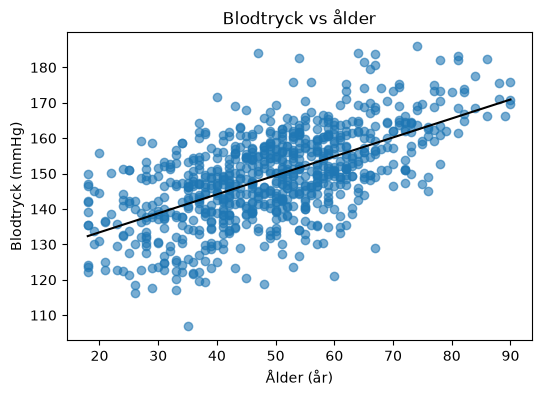

In [12]:
text, results = ha.linear_regression("age", "systolic_bp", 100, "years")

print(text)

ha.plot_regression("age", "systolic_bp", results["intercept"], results["coef"])

Linjär regression visar ett positivt samband mellan ålder och systoliskt blodtryck. Blodtrycket ökar i genomsnitt med **0,54 mmHg per år**. R² = 0,369 betyder att ålder förklarar ca 37 % av variationen i blodtrycket, så även andra faktorer påverkar. Prognosen för 100 år är 176,3 mmHg, men den är osäker eftersom den äldsta personen i datan är 90 år.

### Multipel regression

Linjär regression:
    Intercept = 109.50
    Coefficient = [0.5389276325169823, 0.17765752193267903]
    R² = 0.405


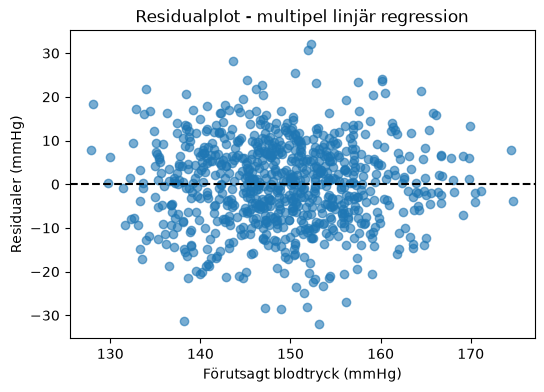

In [13]:
text_m, results_m = ha.linear_regression(["age", "weight"], "systolic_bp")

print(text_m)

ha.plot_residuals(results_m)

Multipel linjär regression med ålder och vikt visar att båda har ett positivt samband med systoliskt blodtryck. Blodtrycket ökar i genomsnitt med **0,54 mmHg per år** och med **0,18 mmHg per kg**, när den andra variabeln hålls lika. R² = 0,405 betyder att modellen förklarar ca 40 % av variationen, vilket är bara ca 4 procentenheter mer än med enbart ålder. Residualplotten visar inget tydligt mönster, så en linjär modell passar rimligt.

## Metodval:

- **Simulering av andel sjuka:** Sjukdom är ja eller nej (0/1), därför simuleras den med binomialfördelning (`rng.binomial`) och sannolikheten från datasetet.

- **Konfidensintervall.** Konfidensintervallet för medelvärdet beräknades med två metoder: t-fördelning och bootstrap. Eftersom blodtryck är en kontinuerlig mätvariabel och vi vill uppskatta medelvärdet, samtidigt som populationens standardavvikelse är okänd, är t-fördelningen lämplig. Bootstrap användes också som en kompletterande metod för att uppskatta konfidensintervallet utan att behöva anta att data är normalfördelade.

- **Hypotesprövning.** Welchs t-test (`equal_var=False`) används eftersom grupperna är olika stora (213 och 587) och testet inte kräver lika varians. Testet är ensidigt (`alternative="greater"`) eftersom hypotesen är att rökare har *högre* blodtryck. Signifikansnivån är α = 0,05.

- **Power-simulering.** Power undersöks genom att simulera normalfördelade grupper med samma n, medelvärde och standardavvikelse som i datasetet och köra samma Welch-test 10 000 gånger. Andelen signifikanta test är power. 80 % power är en vanlig gräns för att ett test ska anses tillräckligt starkt.

- **Linjär regression.** Blodtryck är en kontinuerlig mätvariabel och vi vill beskriva hur det förändras med ålder och vikt, därför är linjär regression lämplig (`LinearRegression`). Modellen anpassades först med enbart ålder (enkel regression) och sedan med både ålder och vikt (multipel regression) för att se om vikt ökar förklaringsgraden. R² visar hur stor del av variationen modellen förklarar, och residualplotten används för att kontrollera att en linjär modell passar.

**Källor:**
- Kursmaterialet
- NumPy-dokumentationen
- SciPy-dokumentationen: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
- Scikit-learn-dokumentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html